In [2]:
import numpy as  np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("diamonds")

In [3]:
print(df.shape)
print(df.isna().sum())
#The data has 53,940 rows and 10 columns, and 0 missing values.

(53940, 10)
carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64


In [ ]:
print((df[["x", "y", "z"]] == 0).sum())
#it is an error and not an outlier: a diamond cannot have a
#length, width or depth of 0 mm. A 0 is impossible, not just
#unusual, so these values are recording errors (missing values
#stored as 0).

x     8
y     7
z    20
dtype: int64


In [ ]:
rows = ["price", "carat", "depth", "table"]
for name in rows:
    means = round(df[name].mean(), 2)
    medians = round(df[name].median(), 2)
    stds = round(df[name].std(), 2)
    skew = round(df[name].skew(), 2)

    print(name, means, medians, stds, skew) 

#price is the most skewed (1.62). Its mean ($3,933) is above its
#median ($2,401), because a long tail of a few very expensive diamonds
#pulls the mean up, while the median stays at the middle price.

price 3932.8 2401.0 3989.44 1.62
carat 0.8 0.7 0.47 1.12
depth 61.75 61.8 1.43 -0.08
table 57.46 57.0 2.23 0.8


In [36]:
def iqr_mask(series, k=1.5):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    low = q1 - k * iqr
    high = q3 + k * iqr
    outside = (series < low) | (series > high)
    return(outside)

In [37]:
t = pd.Series([1, 2, 3, 4, 100])
print(iqr_mask(t).tolist())

[False, False, False, False, True]


In [49]:
def z_mask(series, threshold=3):
    z = (series - series.mean()) / series.std()
    return z.abs() > threshold

In [ ]:
t = pd.Series([1, 2, 3, 4, 100])
print(z_mask(t).tolist())
#With only 5 values, the biggest possible z-score is 1.79, so a
#z-score above 3 can never happen.The 100 itself inflates the mean (to 22) and the std (to 43.6),
#which pulls its own z-score down. The IQR rule uses Q1 and Q3,
#which the 100 does not move.


[False, False, False, False, False]


In [ ]:
col = ["price", "carat", "depth", "table", "x", "y", "z"]
for i in col:
    a = iqr_mask(df[i])
    b = z_mask(df[i])
    sum1 = a.sum()
    sum2 = b.sum()
    flaggBoth = (a & b).sum()
    flagZscore = (~a & b).sum()
    flagIQR = (a & ~b).sum()

    print(i, sum1, sum2, flaggBoth, flagIQR, flagZscore)

price 3540 1206 1206 2334 0
carat 1889 439 439 1450 0
depth 2545 685 685 1860 0
table 605 336 336 269 0
x 32 43 32 0 11
y 29 34 29 0 5
z 49 55 49 0 6


1. For price, carat, depth and table the IQR rule flags many more
    values (for example price 3540 vs 1206). In these columns, every
    value the z-score flags is also flagged by the IQR rule.
    In skewed columns the long tail inflates the std, so the z fence
    (mean + 3 std) lies far out; the IQR fence is built from Q1 and
    Q3, which the tail does not move.
2. For x, y and z the z-score rule flags more (43 vs 32, 34 vs 29,
    55 vs 49). In these columns the z fences are slightly tighter
    than the IQR fences (for x the upper fence is 9.10 for z and 9.28
    for IQR).
3. Yes. The z-score rule found values the IQR rule missed only in
    x (11), y (5) and z (6). In the other four columns it found none.


In [80]:
def price_fence(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    stds = series.std()
    means = series.mean()
    iqr_upper = q3 + 1.5 * iqr
    iqr_lower = q1 - 1.5 * iqr
    z_upper = means + 3 * stds
    z_lower = means - 3 * stds
    return q1, q3, iqr_lower, iqr_upper, z_lower, z_upper

In [81]:
print(price_fence(df["price"]))

(np.float64(950.0), np.float64(5324.25), np.float64(-5611.375), np.float64(11885.625), np.float64(-8035.5194925259), np.float64(15901.118936352375))


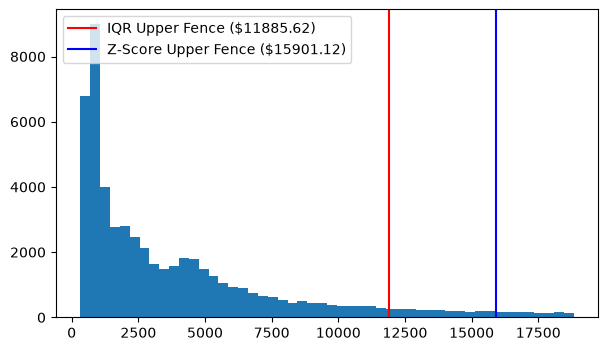

In [ ]:
q1, q3, iqr_lower, iqr_upper, z_lower, z_upper = price_fence(df["price"])

plt.figure(figsize=(7,4))
plt.hist(df["price"], bins=50)
plt.axvline(iqr_upper, color="red", label=f"IQR Upper Fence (${round(iqr_upper, 2)})")
plt.axvline(z_upper, color="blue", label=f"Z-Score Upper Fence (${round(z_upper, 2)})")
plt.legend()
plt.show()


1. Both lower fences are negative, and a price cannot be below 0, so
     no price can fall under them. There are 0 lower outliers: only
     high prices can be flagged.
2. 3540 prices (6.6% of the diamonds) are above the IQR upper fence
    of $11,885.63. 1206 prices (2.2%) are above the z upper fence of
    $15,901.12. The z fence is higher because the long tail of very
    expensive diamonds inflates the std (3989), so mean + 3 std lands
    far out. The IQR fence depends on Q3, which the tail does not move.
3. Neither fence is "the right one". Because price is skewed to the
    right, expensive diamonds are normal, so the IQR rule flags many
    real diamonds (6.6%). The z rule gives a shorter list (2.2%), but
    its fence is itself pushed up by the tail (the same effect that
    hid the 100 in Part 2), so it is not "adapting to the data",
    it is being distorted by it. A common approach for skewed data
    is to apply the rule to log(price) instead of price.
    Either way, the flagged high prices are real diamonds, so I would
    keep them.


In [ ]:
print(df[df["y"] > 20][["carat", "price", "x", "y", "z"]])

       carat  price     x     y     z
24067   2.00  12210  8.09  58.9  8.06
49189   0.51   2075  5.15  31.8  5.12


1  The two rows with y > 20:
    y = 58.9 (carat 2.00, price $12,210, x = 8.09, z = 8.06)
    y = 31.8 (carat 0.51, price $2,075, x = 5.15, z = 5.12)
    Your reasoning was right: in each row x and z are almost equal,
    so y should be close to them (about 8 and about 5). A width of
    58.9 mm (nearly 6 cm) or 31.8 mm is impossible for a 2 carat
    and a 0.51 carat stone. These are typing mistakes.
    One correction: do not guess the real value. "5.89" and
    "3.18" do not fit x and z in the same rows (about 8 and about
    5), so we cannot know the true value. We only know the value
    is wrong.


In [ ]:
print((df["carat"].nlargest(5)))

27415    5.01
27630    4.50
27130    4.13
25998    4.01
25999    4.01
Name: carat, dtype: float64


2  The largest carat values are 5.01, 4.50, 4.13, 4.01, 4.01.
    A 5.01 carat diamond is rare but real, so it is an extreme
    value and not an error. Keep it.
    For the y = 58.9 and y = 31.8 rows: drop the 2 rows (2 of
    53,940) or set y to missing. The same decision applies to the
    20 rows that have a 0 in x, y or z.



## Conclusion

Findings
1. For price, the IQR rule flags 3540 diamonds (6.6%) and the z-score
   rule flags 1206 (2.2%), and every diamond flagged by z is also
   flagged by IQR. Price is skewed to the right (mean $3,933 vs median
   $2,401), and the long tail inflates the std, so the z fence
   ($15,901) is much higher than the IQR fence ($11,886).
2. The same pattern holds for carat (1889 vs 439), depth (2545 vs 685)
   and table (605 vs 336). Only for x, y and z does the z-score rule
   flag a few more values (43 vs 32, 34 vs 29, 55 vs 49), because the
   z fences are slightly tighter there.
3. The data contains real errors that the methods only hint at: 2
   diamonds with an impossible width (y = 58.9 and 31.8 mm, while x and
   z in the same rows are about 8 and 5 mm) and 20 rows where length,
   width or depth is 0.

Decisions
- price: I trust the IQR rule more, because the tail does not distort
  its fence. I would keep the flagged values, because expensive
  diamonds are real data. If I had to remove extremes for a model, I
  would apply the rule to log(price).
- carat: I would use the IQR rule again. The flagged values include
  real large diamonds (the largest is 5.01 carat), so I would keep
  them.
- y: both methods catch the two impossible widths. I would use the IQR
  rule first (the 58.9 does not distort it) and remove the 2 rows (or
  set y to missing), together with the rows where a dimension is 0.

Caveat
- IQR and z-score only find UNUSUAL values. They cannot tell whether a
  value is an error. For that I had to compare y with x and z in the
  same row, which needs knowledge of the data.
